In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import json
from scipy import stats

C1 = "#2a78d6"  # blau
C2 = "#1baf7a"  # grün
C3 = "#eda100"  # gelb
C4 = "#e34948"  # rot
C5 = "#4a3aa7"  # violett
MUTED = "#898781"
GRID  = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor":   "#fcfcfb",
    "axes.edgecolor":   "#c3c2b7",
    "axes.linewidth":   0.8,
    "grid.color":       GRID,
    "grid.linewidth":   0.6,
    "xtick.color":      MUTED,
    "ytick.color":      MUTED,
    "text.color":       "#0b0b0b",
    "font.size":        11,
})

In [3]:
baseline = pd.read_csv("../results/nas_baseline.csv")
proxies = pd.read_csv("../results/nas_proxies.csv")
proxy_val = pd.read_csv("../results/proxy_validation.csv")
f1 = pd.read_csv("../results/f1_scaling.csv")

with open("../results/retrain_analysis_summary.json") as f:
    retrain = pd.DataFrame(json.load(f))

with open("../results/spt_ablation_summary.json") as f:
    spt_raw = json.load(f)
    
print(f"nas_baseline:     {len(baseline)} Architekturen")
print(f"nas_proxies:      {len(proxies)} Architekturen")
print(f"proxy_validation: {len(proxy_val)} Architekturen")
print(f"f1_scaling:       {len(f1)} Einträge")


nas_baseline:     120 Architekturen
nas_proxies:      56 Architekturen
proxy_validation: 100 Architekturen
f1_scaling:       24 Einträge


In [4]:
def pareto_front(df, acc_col="val_acc", param_col="params"):
    """Gibt Boolean-Maske zurück: True = Pareto-optimal."""
    n = len(df)
    is_pareto = np.ones(n, dtype=bool)
    acc = df[acc_col].values
    par = df[param_col].values
    for i in range(n):
        for j in range(n):
            if i == j: continue
            if acc[j] >= acc[i] and par[j] <= par[i] and (acc[j] > acc[i] or par[j] < par[i]):
                is_pareto[i] = False
                break
    return is_pareto


## Pareto-Front NAS Baseline

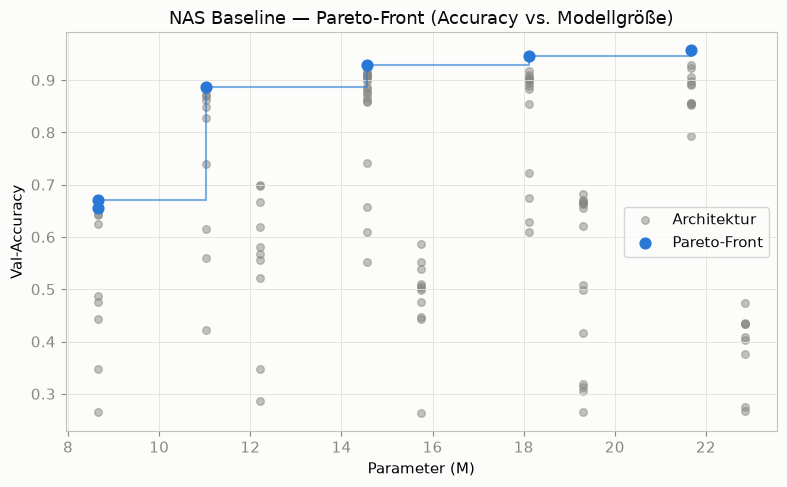

In [6]:
mask = pareto_front(baseline)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline.loc[~mask, "params"] / 1e6,
           baseline.loc[~mask, "val_acc"],
           color=MUTED, alpha=0.5, s=30, label="Architektur")
ax.scatter(baseline.loc[mask, "params"] / 1e6,
           baseline.loc[mask, "val_acc"],
           color=C1, s=60, zorder=5, label="Pareto-Front")

pf = baseline[mask].sort_values("params")
ax.step(pf["params"] / 1e6, pf["val_acc"],
        where="post", color=C1, linewidth=1.5, alpha=0.6)

ax.set_xlabel("Parameter (M)")
ax.set_ylabel("Val-Accuracy")
ax.set_title("NAS Baseline — Pareto-Front (Accuracy vs. Modellgröße)")
ax.legend()
ax.grid(True, axis="both")
plt.tight_layout()
plt.savefig("../results/plots/pareto_baseline.png", dpi=150)
plt.show()

## Baseline vs. Proxies (beide Pareto-Fronten)

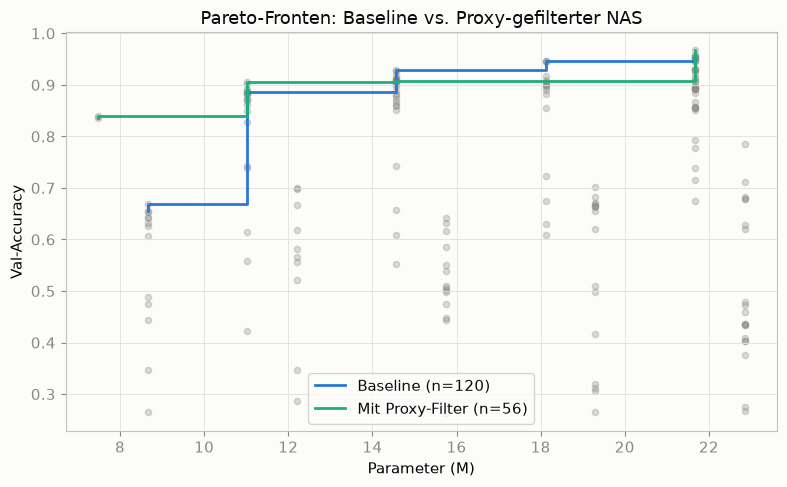

In [7]:
mask_b = pareto_front(baseline)
mask_p = pareto_front(proxies)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline["params"] / 1e6, baseline["val_acc"],
           color=MUTED, alpha=0.3, s=20)
ax.scatter(proxies["params"] / 1e6, proxies["val_acc"],
           color=MUTED, alpha=0.3, s=20)

pf_b = baseline[mask_b].sort_values("params")
pf_p = proxies[mask_p].sort_values("params")

ax.step(pf_b["params"] / 1e6, pf_b["val_acc"],
        where="post", color=C1, linewidth=2, label=f"Baseline (n=120)")
ax.step(pf_p["params"] / 1e6, pf_p["val_acc"],
        where="post", color=C2, linewidth=2, label=f"Mit Proxy-Filter (n={len(proxies)})")

ax.set_xlabel("Parameter (M)"); ax.set_ylabel("Val-Accuracy")
ax.set_title("Pareto-Fronten: Baseline vs. Proxy-gefilterter NAS")
ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/pareto_vergleich.png", dpi=150)
plt.show()


## Proxy Validation Scatter (3 Subplots)

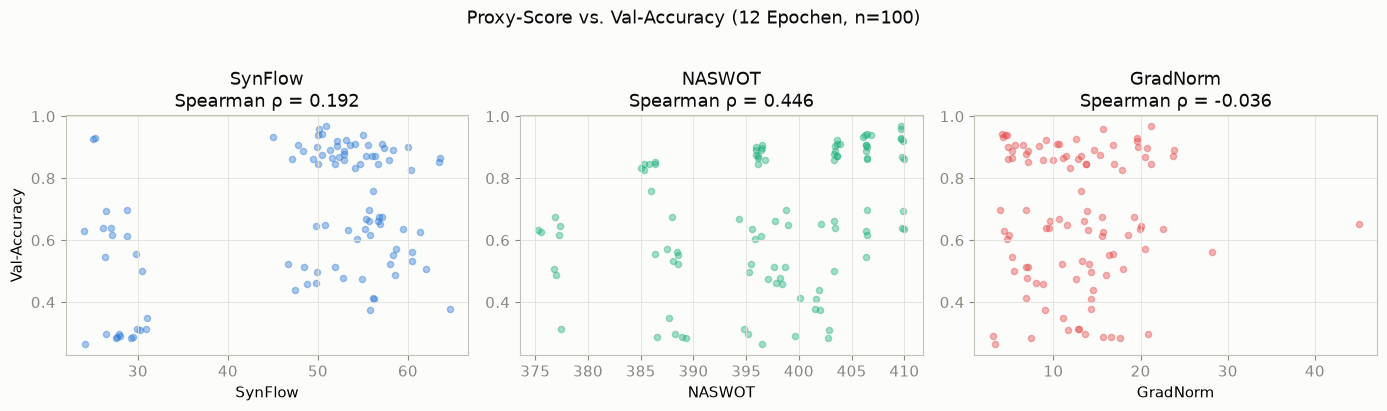

In [10]:
proxies_list = [
    ("synflow",  "SynFlow",  C1),
    ("naswot",   "NASWOT",   C2),
    ("gradnorm", "GradNorm", C4),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, label, color) in zip(axes, proxies_list):
    x = proxy_val[col]
    y = proxy_val["val_acc"]
    rho, pval = stats.spearmanr(x, y)
    ax.scatter(x, y, color=color, alpha=0.4, s=20)
    ax.set_xlabel(label)
    ax.set_ylabel("Val-Accuracy" if ax == axes[0] else "")
    ax.set_title(f"{label}\nSpearman ρ = {rho:.3f}")
    ax.grid(True)

plt.suptitle("Proxy-Score vs. Val-Accuracy (12 Epochen, n=100)", y=1.02)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


#### Synflow

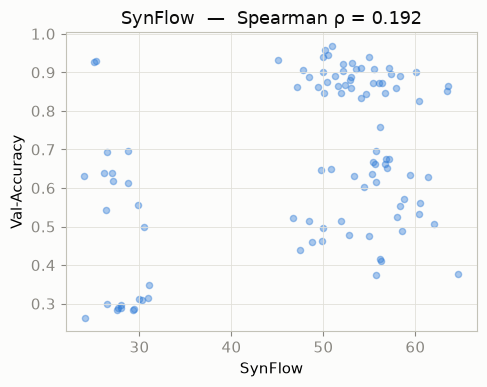

In [9]:
x = proxy_val["synflow"]
y = proxy_val["val_acc"]
rho, pval = stats.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color=C1, alpha=0.4, s=20)
ax.set_xlabel("SynFlow")
ax.set_ylabel("Val-Accuracy")
ax.set_title(f"SynFlow  —  Spearman ρ = {rho:.3f}")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter_synflow.png", dpi=150)
plt.show()

#### NASWOT

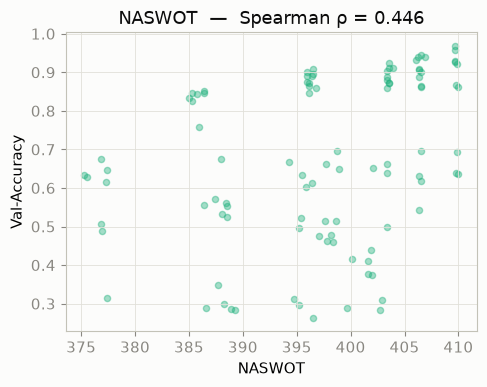

In [11]:
x = proxy_val["naswot"]
y = proxy_val["val_acc"]
rho, pval = stats.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color=C2, alpha=0.4, s=20)
ax.set_xlabel("NASWOT")
ax.set_ylabel("Val-Accuracy")
ax.set_title(f"NASWOT  —  Spearman ρ = {rho:.3f}")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter_naswot.png", dpi=150)
plt.show()

#### GradNorm

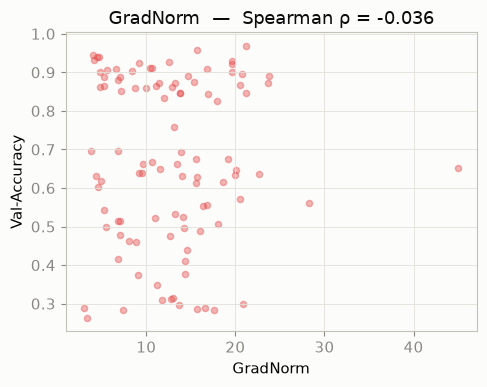

In [12]:
x = proxy_val["gradnorm"]
y = proxy_val["val_acc"]
rho, pval = stats.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color=C4, alpha=0.4, s=20)
ax.set_xlabel("GradNorm")
ax.set_ylabel("Val-Accuracy")
ax.set_title(f"GradNorm  —  Spearman ρ = {rho:.3f}")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter_gradnorm.png", dpi=150)
plt.show()


## F1 Datensatz-Skalierung

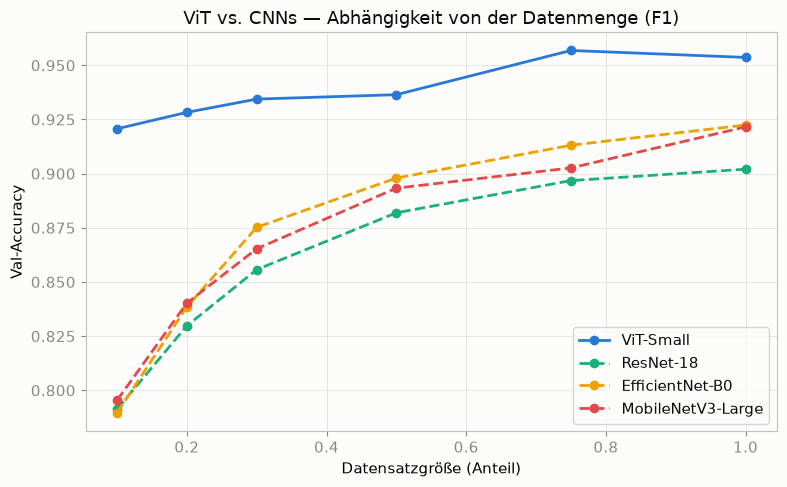

In [13]:
model_styles = {
    "vit_small":          (C1, "-",  "ViT-Small"),
    "resnet18":           (C2, "--", "ResNet-18"),
    "efficientnet_b0":    (C3, "--", "EfficientNet-B0"),
    "mobilenetv3_large":  (C4, "--", "MobileNetV3-Large"),
}

fig, ax = plt.subplots(figsize=(8, 5))
for model, (color, ls, label) in model_styles.items():
    d = f1[f1["model"] == model].sort_values("subsample_frac")
    ax.plot(d["subsample_frac"], d["best_val_acc"],
            color=color, linestyle=ls, linewidth=2,
            marker="o", markersize=6, label=label)

ax.set_xlabel("Datensatzgröße (Anteil)")
ax.set_ylabel("Val-Accuracy")
ax.set_title("ViT vs. CNNs — Abhängigkeit von der Datenmenge (F1)")
ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/f1_scaling.png", dpi=150)
plt.show()


## SPT-Ablation Lernkurven

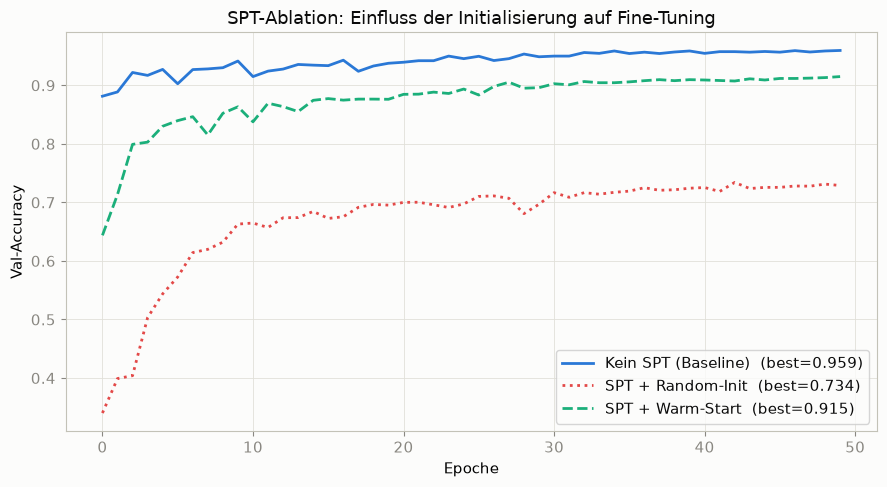

In [14]:
spt_styles = {
    "spt_none":   (C1, "-",  "Kein SPT (Baseline)"),
    "spt_warm":   (C2, "--", "SPT + Warm-Start"),
    "spt_random": (C4, ":",  "SPT + Random-Init"),
}

fig, ax = plt.subplots(figsize=(9, 5))
for entry in spt_raw:
    label_key = entry["label"]
    color, ls, label = spt_styles[label_key]
    epochs = [h["epoch"] for h in entry["history"]]
    vals   = [h["val_acc"] for h in entry["history"]]
    ax.plot(epochs, vals, color=color, linestyle=ls,
            linewidth=2, label=f"{label}  (best={entry['val_acc']:.3f})")

ax.set_xlabel("Epoche"); ax.set_ylabel("Val-Accuracy")
ax.set_title("SPT-Ablation: Einfluss der Initialisierung auf Fine-Tuning")
ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/spt_ablation.png", dpi=150)
plt.show()

## Retrain-Analyse

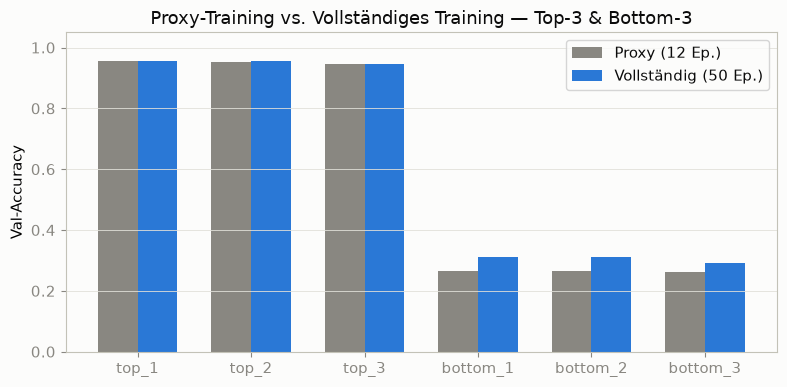

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(retrain))
w = 0.35

ax.bar(x - w/2, retrain["proxy_val_acc"], w, color=MUTED, label="Proxy (12 Ep.)")
ax.bar(x + w/2, retrain["full_val_acc"],  w, color=C1,    label="Vollständig (50 Ep.)")

ax.set_xticks(x)
ax.set_xticklabels(retrain["label"])
ax.set_ylabel("Val-Accuracy")
ax.set_title("Proxy-Training vs. Vollständiges Training — Top-3 & Bottom-3")
ax.legend(); ax.grid(True, axis="y")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("../results/plots/retrain_vergleich.png", dpi=150)
plt.show()


## Boxplots pro Parameter

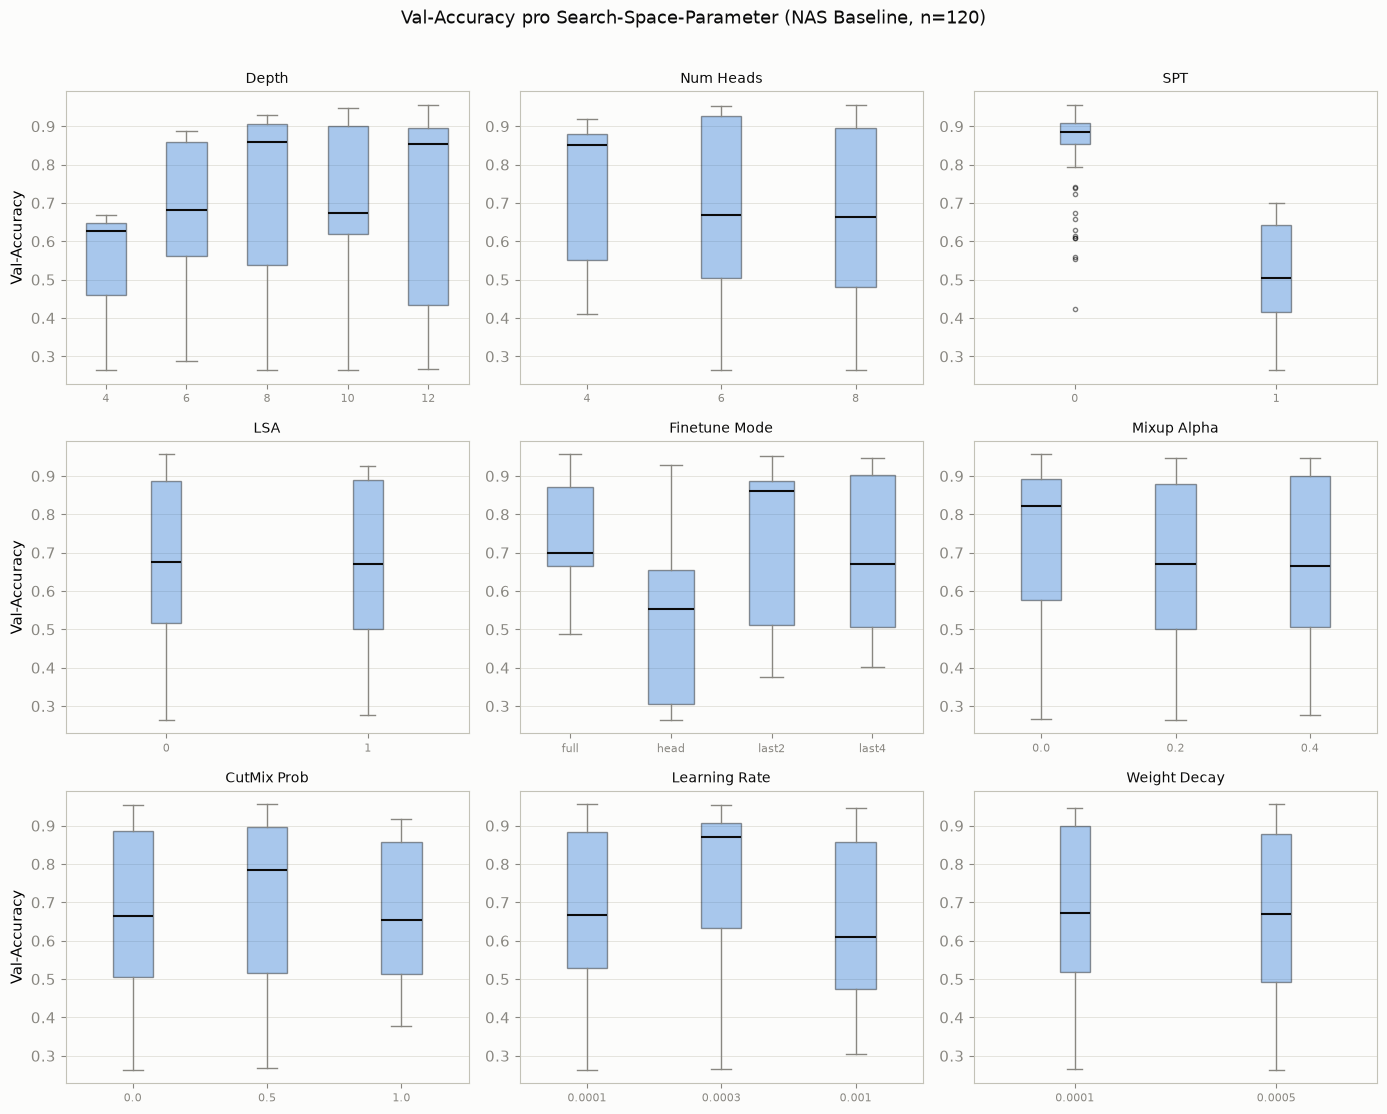

In [19]:
params = {
    "depth":        "Depth",
    "num_heads":    "Num Heads",
    "use_spt":      "SPT",
    "use_lsa":      "LSA",
    "finetune_mode":"Finetune Mode",
    "mixup_alpha":  "Mixup Alpha",
    "cutmix_prob":  "CutMix Prob",
    "lr":           "Learning Rate",
    "weight_decay": "Weight Decay",
}

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for ax, (col, label) in zip(axes, params.items()):
    groups = [baseline.loc[baseline[col] == v, "val_acc"].values
              for v in sorted(baseline[col].unique())]
    labels = [str(v) for v in sorted(baseline[col].unique())]

    bp = ax.boxplot(groups, tick_labels=labels, patch_artist=True,
                    medianprops=dict(color="#0b0b0b", linewidth=1.5),
                    boxprops=dict(facecolor=C1, alpha=0.4),
                    whiskerprops=dict(color=MUTED),
                    capprops=dict(color=MUTED),
                    flierprops=dict(marker="o", color=MUTED, markersize=3, alpha=0.5))

    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Val-Accuracy" if ax in axes[::3] else "")
    ax.grid(True, axis="y")
    ax.tick_params(axis="x", labelsize=8)

plt.suptitle("Val-Accuracy pro Search-Space-Parameter (NAS Baseline, n=120)", y=1.01)
plt.tight_layout()
plt.savefig("../results/plots/boxplots_parameter.png", dpi=150, bbox_inches="tight")
plt.show()


## Parameter-Einflussranking

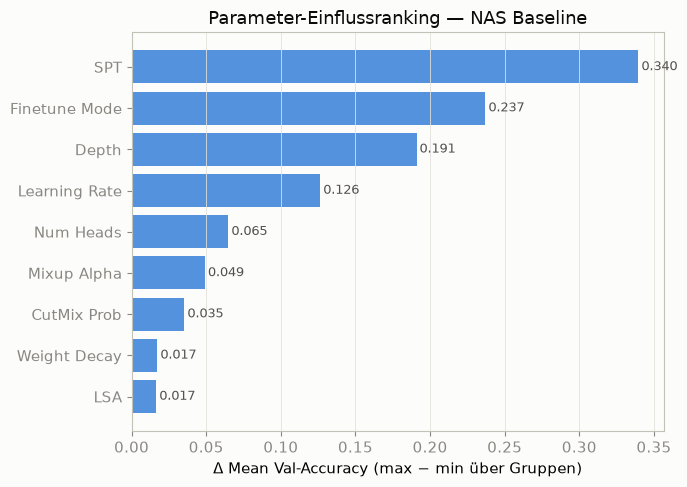

use_spt          0.339612
finetune_mode    0.237089
depth            0.190900
lr               0.126407
num_heads        0.064845
mixup_alpha      0.049139
cutmix_prob      0.035385
weight_decay     0.017276
use_lsa          0.016537


In [20]:
influence = {}
for col in params:
    means = baseline.groupby(col)["val_acc"].mean()
    influence[col] = means.max() - means.min()

inf_df = pd.Series(influence, name="Einfluss (Δ mean val_acc)") \
           .sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.barh(
    [params[k] for k in inf_df.index],
    inf_df.values,
    color=C1, alpha=0.8
)

# Werte direkt auf die Balken
for bar, val in zip(bars, inf_df.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=9, color="#52514e")

ax.set_xlabel("Δ Mean Val-Accuracy (max − min über Gruppen)")
ax.set_title("Parameter-Einflussranking — NAS Baseline")
ax.grid(True, axis="x")
plt.tight_layout()
plt.savefig("../results/plots/parameter_einfluss.png", dpi=150)
plt.show()

print(inf_df.sort_values(ascending=False).to_string())


Differenz zwischen dem besten und schlechtesten Gruppen-Mittelwert für diesen Parameter.

Konkret für use_spt = 0.339:

Architekturen mit use_spt=0 haben im Mittel val_acc X
Architekturen mit use_spt=1 haben im Mittel val_acc X − 0.339
Die Wahl SPT ja/nein verändert die durchschnittliche Val-Accuracy um 33.9 Prozentpunkte
Das ist der stärkste Einflussfaktor — was direkt mit dem SPT-Ablation-Ergebnis zusammenpasst: SPT mit random init zerstört die pretrained Features.

finetune_mode = 0.237: Je nach Finetune-Modus (head / last2 / last4 / full) schwankt die mittlere Val-Accuracy um 23.7 pp. Welcher Modus am besten ist sieht man im Boxplot.

depth = 0.191: Zwischen flachsten (depth=4) und tiefsten (depth=12) Architekturen liegen 19 pp im Mittel.

lr = 0.126: Die Lernrate beeinflusst das Ergebnis mehr als die Kopfanzahl — interessant, weil lr oft als "nur Hyperparameter" gilt.

use_lsa = 0.017: LSA hat quasi keinen messbaren Einfluss — ähnlich wie SPT ist es wahrscheinlich nicht mit dem Fine-Tuning-Paradigma kompatibel, aber der Effekt ist viel schwächer weil LSA keine Layer-Shape verändert

## Pareto-Front-Zusammensetzung

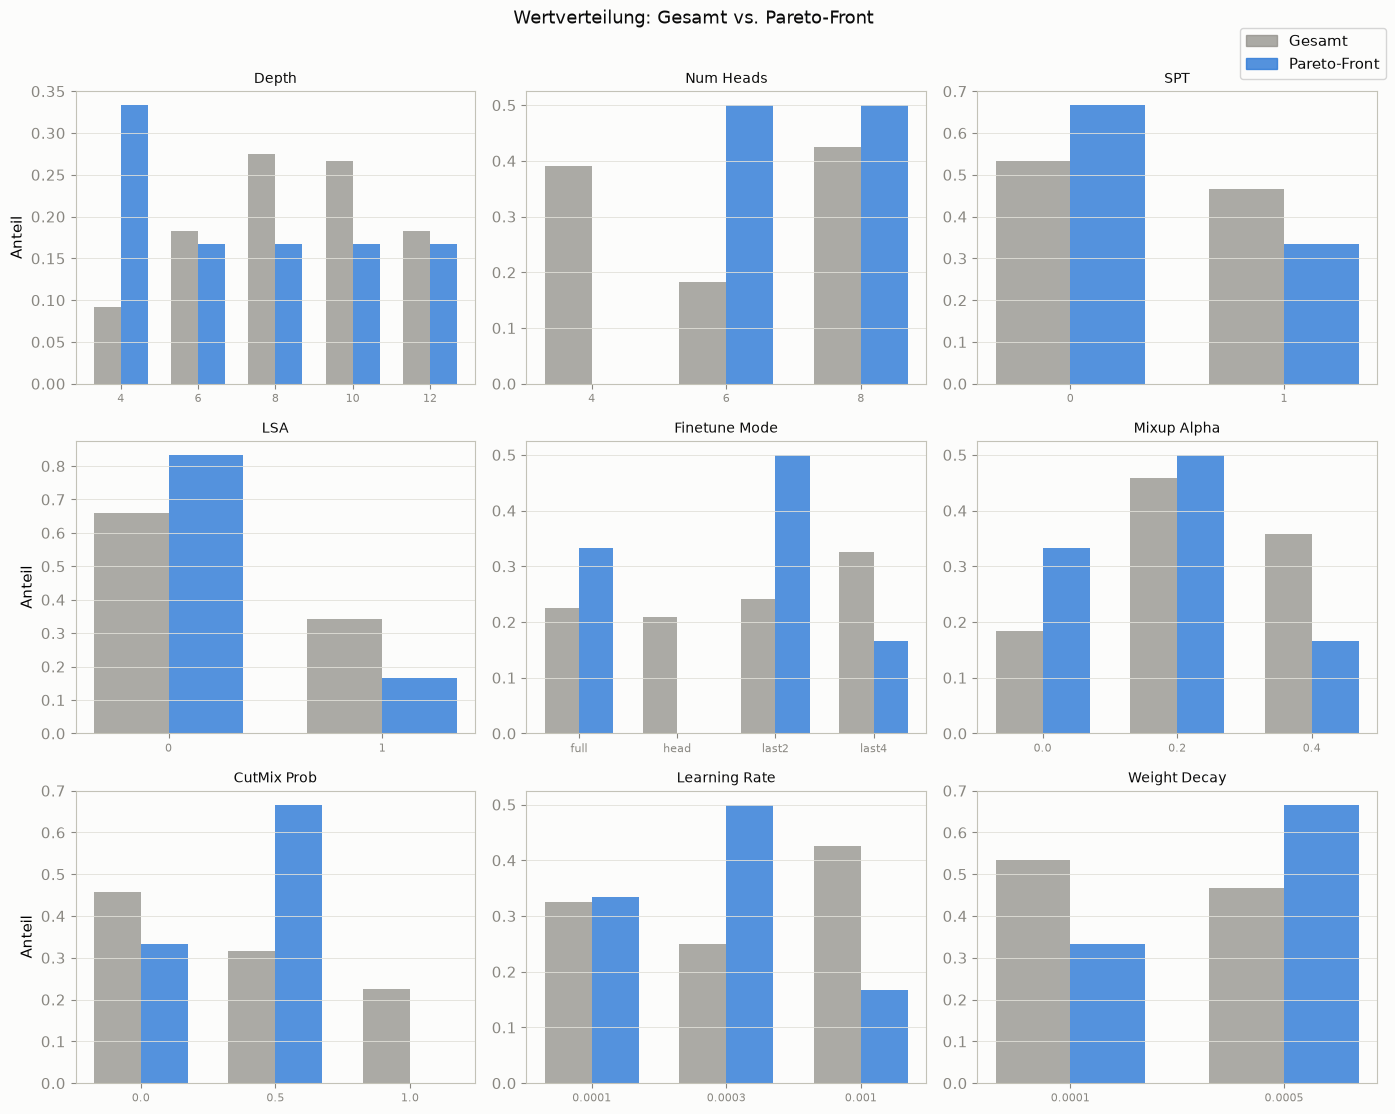

In [21]:
mask = pareto_front(baseline)
pareto_df = baseline[mask]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for ax, (col, label) in zip(axes, params.items()):
    values = sorted(baseline[col].unique())
    
    total_frac  = [len(baseline[baseline[col] == v]) / len(baseline) for v in values]
    pareto_frac = [len(pareto_df[pareto_df[col] == v]) / max(len(pareto_df), 1) for v in values]
    
    x = np.arange(len(values))
    w = 0.35
    ax.bar(x - w/2, total_frac,  w, color=MUTED, alpha=0.7, label="Gesamt")
    ax.bar(x + w/2, pareto_frac, w, color=C1,    alpha=0.8, label="Pareto-Front")
    
    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in values], fontsize=8)
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Anteil" if ax in axes[::3] else "")
    ax.grid(True, axis="y")

handles = [mpatches.Patch(color=MUTED, alpha=0.7, label="Gesamt"),
           mpatches.Patch(color=C1,    alpha=0.8, label="Pareto-Front")]
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(1.0, 1.0))
plt.suptitle("Wertverteilung: Gesamt vs. Pareto-Front", y=1.01)
plt.tight_layout()
plt.savefig("../results/plots/pareto_komposition.png", dpi=150, bbox_inches="tight")
plt.show()


## Heatmap depth × finetune_mode

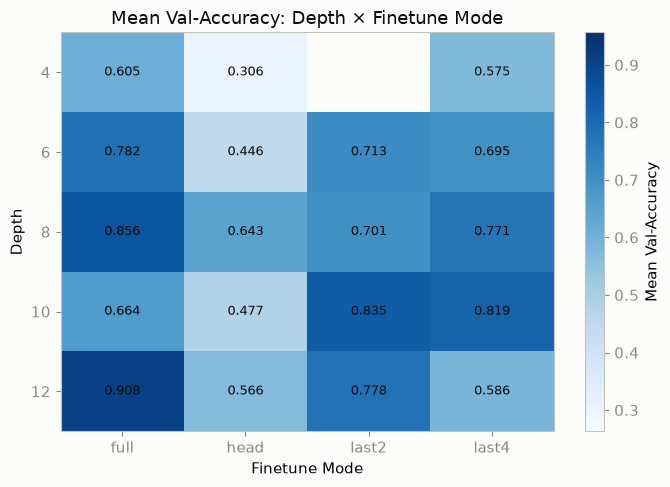

In [22]:
pivot = baseline.pivot_table(
    values="val_acc",
    index="depth",
    columns="finetune_mode",
    aggfunc="mean"
)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto",
               vmin=baseline["val_acc"].min(),
               vmax=baseline["val_acc"].max())

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Finetune Mode")
ax.set_ylabel("Depth")
ax.set_title("Mean Val-Accuracy: Depth × Finetune Mode")

# Werte in Zellen
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                    fontsize=9, color="#0b0b0b")

plt.colorbar(im, ax=ax, label="Mean Val-Accuracy")
plt.tight_layout()
plt.savefig("../results/plots/heatmap_depth_finetune.png", dpi=150)
plt.show()


# F1 Crossover Analyse (Wann schlägt ViT die CNNs)

In [8]:
cnn_models = ["resnet18", "efficientnet_b0", "mobilenetv3_large"]
vit = f1[f1["model"] == "vit_small"].sort_values("subsample_frac")

print("=== F1: ViT vs. CNN — Val-Accuracy pro Datensatzgröße ===\n")
header = f"{'frac':>6}  {'train_n':>8}  {'ViT':>8}" + \
         "".join(f"  {m[:10]:>12}" for m in cnn_models)
print(header)
print("-" * len(header))

crossovers = {m: None for m in cnn_models}

for _, row in vit.iterrows():
    frac = row["subsample_frac"]
    vit_acc = row["best_val_acc"]
    train_n = int(row["train_size"])
    line = f"{frac:>6.2f}  {train_n:>8d}  {vit_acc:>8.4f}"
    for m in cnn_models:
        cnn_row = f1[(f1["model"] == m) & (f1["subsample_frac"] == frac)]
        if len(cnn_row):
            cnn_acc = cnn_row["best_val_acc"].values[0]
            diff = vit_acc - cnn_acc
            marker = " ✓" if diff > 0 else "  "
            line += f"  {cnn_acc:>10.4f}{marker}"
            if diff > 0 and crossovers[m] is None:
                crossovers[m] = frac
    print(line)

print("\n=== Crossover-Punkte (erster frac wo ViT > CNN) ===")
for m, frac in crossovers.items():
    if frac:
        n = int(f1[(f1["model"] == m) & (f1["subsample_frac"] == frac)]["train_size"].values[0])
        print(f"  ViT > {m:<25} ab frac={frac}  (~{n} Trainingsbilder)")
    else:
        print(f"  ViT > {m:<25} NIE")


=== F1: ViT vs. CNN — Val-Accuracy pro Datensatzgröße ===

  frac   train_n       ViT      resnet18    efficientn    mobilenetv
--------------------------------------------------------------------
  0.10       986    0.9207      0.7913 ✓      0.7895 ✓      0.7953 ✓
  0.20      1973    0.9283      0.8297 ✓      0.8385 ✓      0.8402 ✓
  0.30      2959    0.9344      0.8557 ✓      0.8752 ✓      0.8653 ✓
  0.50      4933    0.9364      0.8819 ✓      0.8980 ✓      0.8933 ✓
  0.75      7399    0.9569      0.8968 ✓      0.9131 ✓      0.9026 ✓
  1.00      9866    0.9536      0.9020 ✓      0.9224 ✓      0.9216 ✓

=== Crossover-Punkte (erster frac wo ViT > CNN) ===
  ViT > resnet18                  ab frac=0.1  (~986 Trainingsbilder)
  ViT > efficientnet_b0           ab frac=0.1  (~986 Trainingsbilder)
  ViT > mobilenetv3_large         ab frac=0.1  (~986 Trainingsbilder)


#### Plot mit Crossover-Markierung:

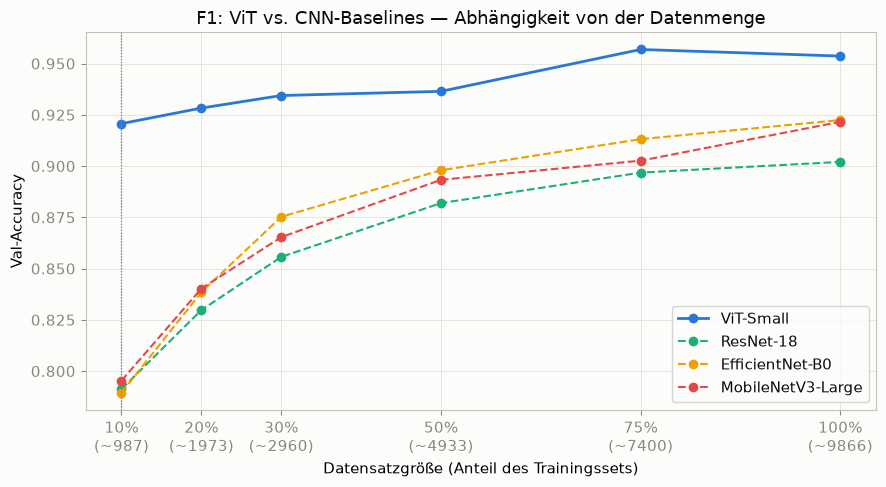

In [7]:
model_styles = {
    "vit_small":           (C1, "-",  2.0, "ViT-Small"),
    "resnet18":            (C2, "--", 1.5, "ResNet-18"),
    "efficientnet_b0":     (C3, "--", 1.5, "EfficientNet-B0"),
    "mobilenetv3_large":   (C4, "--", 1.5, "MobileNetV3-Large"),
}

fig, ax = plt.subplots(figsize=(9, 5))

for model, (color, ls, lw, label) in model_styles.items():
    d = f1[f1["model"] == model].sort_values("subsample_frac")
    ax.plot(d["subsample_frac"], d["best_val_acc"],
            color=color, linestyle=ls, linewidth=lw,
            marker="o", markersize=6, label=label)

# Crossover-Linien einzeichnen
for m, frac in crossovers.items():
    if frac:
        ax.axvline(frac, color=MUTED, linewidth=0.8, linestyle=":")

ax.set_xlabel("Datensatzgröße (Anteil des Trainingssets)")
ax.set_ylabel("Val-Accuracy")
ax.set_title("F1: ViT vs. CNN-Baselines — Abhängigkeit von der Datenmenge")
ax.legend(loc="lower right")
ax.grid(True)
ax.set_xticks([0.1, 0.2, 0.3, 0.5, 0.75, 1.0])
ax.set_xticklabels(["10%\n(~987)", "20%\n(~1973)", "30%\n(~2960)",
                     "50%\n(~4933)", "75%\n(~7400)", "100%\n(~9866)"])
plt.tight_layout()
plt.savefig("../results/plots/f1_crossover.png", dpi=150, bbox_inches="tight")
plt.show()


In [9]:
cnn_labels = {
    "resnet18":           "ResNet-18",
    "efficientnet_b0":    "EfficientNet-B0",
    "mobilenetv3_large":  "MobileNetV3-Large",
}

rows = []
for frac in sorted(f1["subsample_frac"].unique()):
    vit_acc = f1[(f1["model"] == "vit_small") & (f1["subsample_frac"] == frac)]["best_val_acc"].values[0]
    train_n = int(f1[(f1["model"] == "vit_small") & (f1["subsample_frac"] == frac)]["train_size"].values[0])
    row = {"Datensatzgröße": f"{int(frac*100):>3}%  ({train_n:>5} Bilder)", "ViT-Small": f"{vit_acc:.4f}"}
    for cnn, label in cnn_labels.items():
        cnn_acc = f1[(f1["model"] == cnn) & (f1["subsample_frac"] == frac)]["best_val_acc"].values[0]
        row[label] = f"{cnn_acc:.4f}"
        row[f"Δ {label.split('-')[0]}"] = f"+{vit_acc - cnn_acc:.3f}"
    rows.append(row)

delta_df = pd.DataFrame(rows).set_index("Datensatzgröße")
print("Val-Accuracy und Vorsprung des ViT-Small gegenüber CNN-Baselines\n")
print(delta_df.to_string())

Val-Accuracy und Vorsprung des ViT-Small gegenüber CNN-Baselines

                     ViT-Small ResNet-18 Δ ResNet EfficientNet-B0 Δ EfficientNet MobileNetV3-Large Δ MobileNetV3
Datensatzgröße                                                                                                  
 10%  (  986 Bilder)    0.9207    0.7913   +0.129          0.7895         +0.131            0.7953        +0.125
 20%  ( 1973 Bilder)    0.9283    0.8297   +0.099          0.8385         +0.090            0.8402        +0.088
 30%  ( 2959 Bilder)    0.9344    0.8557   +0.079          0.8752         +0.059            0.8653        +0.069
 50%  ( 4933 Bilder)    0.9364    0.8819   +0.055          0.8980         +0.038            0.8933        +0.043
 75%  ( 7399 Bilder)    0.9569    0.8968   +0.060          0.9131         +0.044            0.9026        +0.054
100%  ( 9866 Bilder)    0.9536    0.9020   +0.052          0.9224         +0.031            0.9216        +0.032


## Top-1-Architektur aus NAS extrahieren

In [25]:
top1 = baseline.sort_values("val_acc", ascending=False).iloc[0]

param_labels = {
    "depth": "Tiefe (Anzahl Blöcke)",
    "num_heads": "Anzahl Attention-Heads",
    "use_spt": "Shifted Patch Tokenization",
    "use_lsa": "Local Self-Attention",
    "finetune_mode": "Finetune-Modus",
    "mixup_alpha": "Mixup Alpha",
    "cutmix_prob": "CutMix Wahrscheinlichkeit",
    "lr": "Lernrate",
    "weight_decay": "Weight Decay",
}

print("=== Beste NAS-Architektur (top_1) ===\n")
print(f"  Proxy Val-Accuracy (12 Ep.): {top1['val_acc']:.4f}")
print(f"  Full  Val-Accuracy (50 Ep.): 0.9554")
print(f"  Test-Accuracy      (50 Ep.): 0.9692")
print(f"  Parameter:                   {top1['params']/1e6:.2f}M\n")
print(f"  {'Parameter':<35} {'Wert':>12}")
print("  " + "-" * 50)
for col, label in param_labels.items():
    print(f"  {label:<35} {str(top1[col]):>12}")


=== Beste NAS-Architektur (top_1) ===

  Proxy Val-Accuracy (12 Ep.): 0.9566
  Full  Val-Accuracy (50 Ep.): 0.9554
  Test-Accuracy      (50 Ep.): 0.9692
  Parameter:                   21.67M

  Parameter                                   Wert
  --------------------------------------------------
  Tiefe (Anzahl Blöcke)                         12
  Anzahl Attention-Heads                         8
  Shifted Patch Tokenization                     0
  Local Self-Attention                           0
  Finetune-Modus                              full
  Mixup Alpha                                  0.0
  CutMix Wahrscheinlichkeit                    0.5
  Lernrate                                  0.0001
  Weight Decay                              0.0005


## top_1 vs. CNN-Baselines (Gesamtvergleich bei frac=1.0):

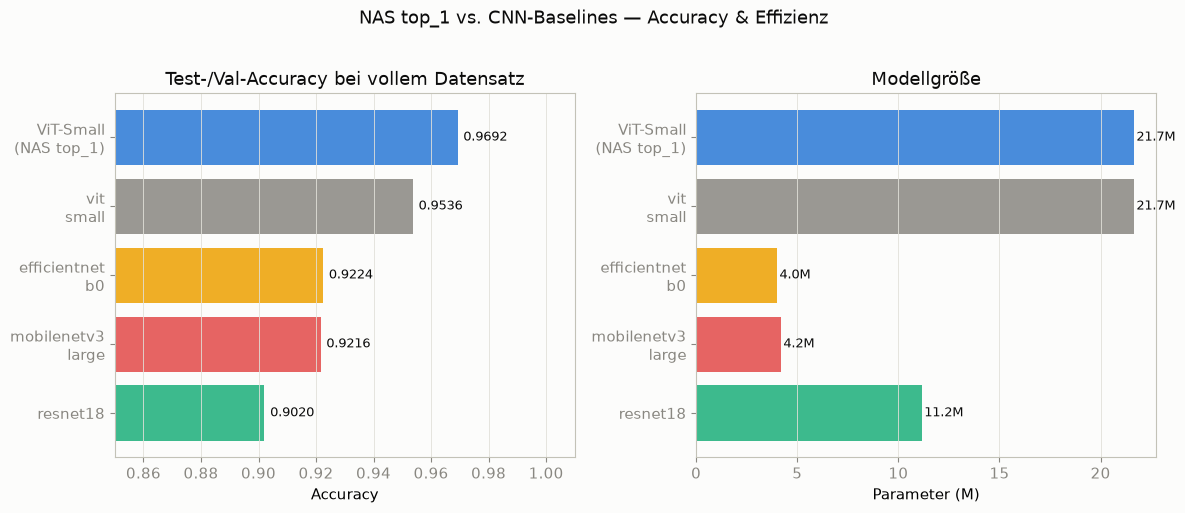

In [26]:
# CNN-Ergebnisse bei frac=1.0
cnn_full = f1[f1["subsample_frac"] == 1.0].copy()

models_compare = []
for _, row in cnn_full.iterrows():
    models_compare.append({
        "label": row["model"].replace("_", "\n"),
        "val_acc": row["best_val_acc"],
        "params_M": row["params_M"],
        "color": {
            "resnet18": C2,
            "efficientnet_b0": C3,
            "mobilenetv3_large": C4,
        }.get(row["model"], MUTED)
    })

# NAS top_1 hinzufügen
models_compare.append({
    "label": "ViT-Small\n(NAS top_1)",
    "val_acc": 0.9692,   # test_acc aus retrain
    "params_M": top1["params"] / 1e6,
    "color": C1
})

models_compare = sorted(models_compare, key=lambda x: x["val_acc"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Val-Accuracy
labels = [m["label"] for m in models_compare]
accs   = [m["val_acc"] for m in models_compare]
colors = [m["color"] for m in models_compare]

bars = axes[0].barh(labels, accs, color=colors, alpha=0.85)
for bar, val in zip(bars, accs):
    axes[0].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                 f"{val:.4f}", va="center", fontsize=9)
axes[0].set_xlabel("Accuracy")
axes[0].set_title("Test-/Val-Accuracy bei vollem Datensatz")
axes[0].set_xlim(0.85, 1.01)
axes[0].grid(True, axis="x")

# Plot 2: Parameteranzahl
params_m = [m["params_M"] for m in models_compare]
bars2 = axes[1].barh(labels, params_m, color=colors, alpha=0.85)
for bar, val in zip(bars2, params_m):
    axes[1].text(val + 0.1, bar.get_y() + bar.get_height()/2,
                 f"{val:.1f}M", va="center", fontsize=9)
axes[1].set_xlabel("Parameter (M)")
axes[1].set_title("Modellgröße")
axes[1].grid(True, axis="x")

plt.suptitle("NAS top_1 vs. CNN-Baselines — Accuracy & Effizienz", y=1.02)
plt.tight_layout()
plt.savefig("../results/plots/nas_vs_cnn.png", dpi=150, bbox_inches="tight")
plt.show()


In [27]:
summary_rows = []
for m in models_compare:
    summary_rows.append({
        "Modell": m["label"].replace("\n", " "),
        "Accuracy": f"{m['val_acc']:.4f}",
        "Parameter (M)": f"{m['params_M']:.1f}",
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Accuracy", ascending=False)
print(summary_df.to_string(index=False))


               Modell Accuracy Parameter (M)
ViT-Small (NAS top_1)   0.9692          21.7
            vit small   0.9536          21.7
      efficientnet b0   0.9224           4.0
    mobilenetv3 large   0.9216           4.2
             resnet18   0.9020          11.2


# NAS Pareto-Front + CNN-Baselines als Referenz:

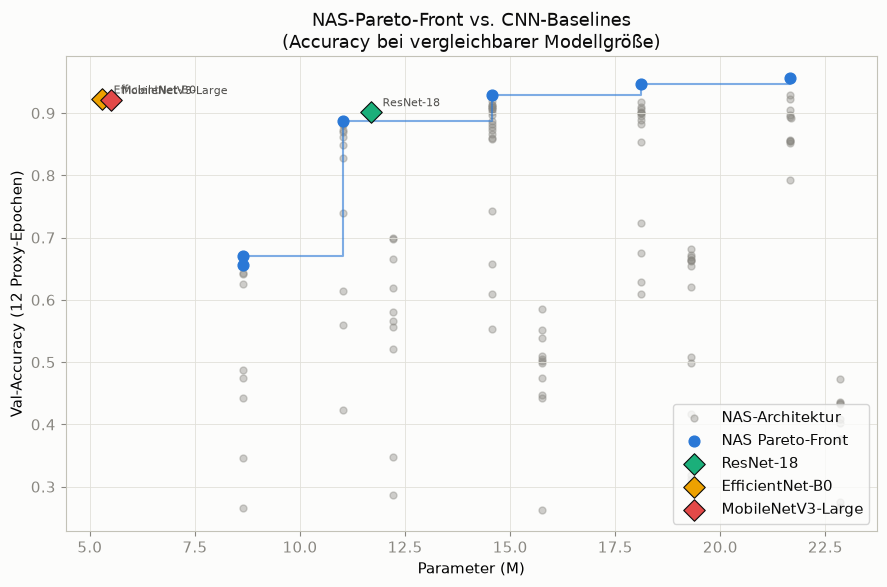

In [7]:
# CNN-Baselines bei frac=1.0
cnn_refs = {
    "ResNet-18":          {"params_M": 11.7, "val_acc": f1[(f1["model"]=="resnet18")         & (f1["subsample_frac"]==1.0)]["best_val_acc"].values[0]},
    "EfficientNet-B0":    {"params_M":  5.3, "val_acc": f1[(f1["model"]=="efficientnet_b0")  & (f1["subsample_frac"]==1.0)]["best_val_acc"].values[0]},
    "MobileNetV3-Large":  {"params_M":  5.5, "val_acc": f1[(f1["model"]=="mobilenetv3_large")& (f1["subsample_frac"]==1.0)]["best_val_acc"].values[0]},
}

mask = pareto_front(baseline)

fig, ax = plt.subplots(figsize=(9, 6))

# Alle NAS-Architekturen
ax.scatter(baseline.loc[~mask, "params"] / 1e6,
           baseline.loc[~mask, "val_acc"],
           color=MUTED, alpha=0.4, s=25, label="NAS-Architektur")

# Pareto-Front
pf = baseline[mask].sort_values("params")
ax.scatter(pf["params"] / 1e6, pf["val_acc"],
           color=C1, s=60, zorder=5, label="NAS Pareto-Front")
ax.step(pf["params"] / 1e6, pf["val_acc"],
        where="post", color=C1, linewidth=1.5, alpha=0.6)

# CNN-Baselines
cnn_colors = [C2, C3, C4]
for (name, data), color in zip(cnn_refs.items(), cnn_colors):
    ax.scatter(data["params_M"], data["val_acc"],
               marker="D", s=120, color=color, zorder=6,
               label=name, edgecolors="#0b0b0b", linewidths=0.8)
    ax.annotate(name,
                xy=(data["params_M"], data["val_acc"]),
                xytext=(8, 4), textcoords="offset points",
                fontsize=8, color="#52514e")

ax.set_xlabel("Parameter (M)")
ax.set_ylabel("Val-Accuracy (12 Proxy-Epochen)")
ax.set_title("NAS-Pareto-Front vs. CNN-Baselines\n(Accuracy bei vergleichbarer Modellgröße)")
ax.legend(loc="lower right")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/pareto_vs_cnn.png", dpi=150)
plt.show()


In [8]:
print("=== NAS-Architekturen mit ≤12M Parametern (vergleichbar mit CNNs) ===\n")

small_nas = baseline[baseline["params"] / 1e6 <= 12.0].copy()
small_nas = small_nas.sort_values("val_acc", ascending=False)

print(f"Anzahl: {len(small_nas)} von {len(baseline)} Architekturen\n")
print(f"{'params_M':>9}  {'val_acc':>9}  {'depth':>6}  {'heads':>6}  {'finetune':>10}  {'spt':>4}  {'lsa':>4}")
print("-" * 65)
for _, row in small_nas.head(10).iterrows():
    print(f"{row['params']/1e6:>9.2f}  {row['val_acc']:>9.4f}  "
          f"{int(row['depth']):>6}  {int(row['num_heads']):>6}  "
          f"{row['finetune_mode']:>10}  {int(row['use_spt']):>4}  {int(row['use_lsa']):>4}")

print(f"\nBeste NAS-Architektur ≤12M:")
best_small = small_nas.iloc[0]
print(f"  Val-Acc: {best_small['val_acc']:.4f}  |  Params: {best_small['params']/1e6:.2f}M")
print(f"\nCNN-Referenzen bei frac=1.0:")
for name, data in cnn_refs.items():
    print(f"  {name:<22}: {data['val_acc']:.4f}  |  {data['params_M']:.1f}M")


=== NAS-Architekturen mit ≤12M Parametern (vergleichbar mit CNNs) ===

Anzahl: 23 von 120 Architekturen

 params_M    val_acc   depth   heads    finetune   spt   lsa
-----------------------------------------------------------------
    11.02     0.8869       6       8       last2     0     0
    11.02     0.8831       6       4       last4     0     0
    11.02     0.8813       6       8        full     0     0
    11.02     0.8720       6       4        full     0     0
    11.02     0.8691       6       4        full     0     1
    11.02     0.8618       6       4       last2     0     1
    11.02     0.8487       6       4       last4     0     0
    11.02     0.8280       6       4        full     0     0
    11.02     0.7394       6       8        full     0     1
     8.65     0.6697       4       8       last4     1     1

Beste NAS-Architektur ≤12M:
  Val-Acc: 0.8869  |  Params: 11.02M

CNN-Referenzen bei frac=1.0:
  ResNet-18             : 0.9020  |  11.7M
  EfficientNet-B0  

## Parametereffizienz-Schwelle: Kleinste NAS-ViT die alle CNNs schlägt

Schwelle (EfficientNet-B0):         val_acc = 0.9224
NAS-Architekturen über Schwelle:   9 / 120
Kleinste winnende ViT:             14.57 M  |  val_acc=0.9289
  depth=8, num_heads=6, finetune_mode=last2


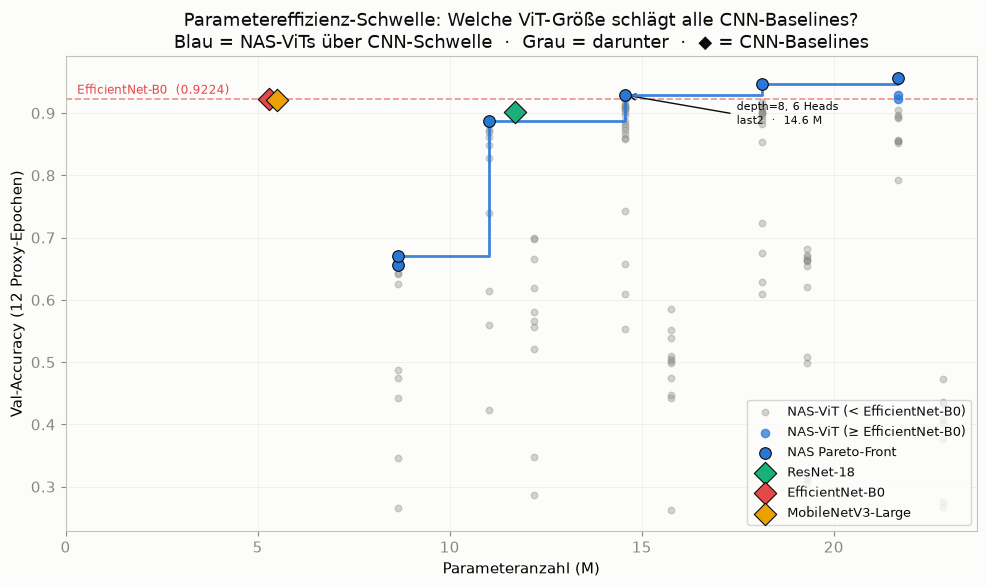

In [ ]:
# Schwelle: beste CNN (aus cnn_refs, frac=1.0)
best_cnn_acc  = max(d["val_acc"] for d in cnn_refs.values())
best_cnn_name = max(cnn_refs, key=lambda k: cnn_refs[k]["val_acc"])

# Partition NAS-Architekturen
nas_below = baseline[baseline["val_acc"] <= best_cnn_acc]
nas_above = baseline[baseline["val_acc"] >  best_cnn_acc]

# Kleinste NAS-ViT die beste CNN schlägt
smallest_winner = nas_above.sort_values("params").iloc[0]
min_params_M    = smallest_winner["params"] / 1e6

print(f"Schwelle ({best_cnn_name}):         val_acc = {best_cnn_acc:.4f}")
print(f"NAS-Architekturen über Schwelle:   {len(nas_above)} / {len(baseline)}")
print(f"Kleinste winnende ViT:             {min_params_M:.2f} M  |  val_acc={smallest_winner['val_acc']:.4f}")
print(f"  depth={int(smallest_winner['depth'])}, num_heads={int(smallest_winner['num_heads'])}, "
      f"finetune_mode={smallest_winner['finetune_mode']}")

mask = pareto_front(baseline)
pf   = baseline[mask].sort_values("params")

fig, ax = plt.subplots(figsize=(10, 6))

# NAS unterhalb Schwelle — grau
ax.scatter(nas_below["params"] / 1e6, nas_below["val_acc"],
           color=MUTED, alpha=0.35, s=22, zorder=2,
           label=f"NAS-ViT (< {best_cnn_name})")

# NAS oberhalb Schwelle — blau
ax.scatter(nas_above["params"] / 1e6, nas_above["val_acc"],
           color=C1, alpha=0.75, s=35, zorder=3,
           label=f"NAS-ViT (≥ {best_cnn_name})")

# Pareto-Front
ax.step(pf["params"] / 1e6, pf["val_acc"],
        where="post", color=C1, linewidth=2.0, alpha=0.9, zorder=4)
ax.scatter(pf["params"] / 1e6, pf["val_acc"],
           color=C1, s=70, zorder=5, edgecolors="#0b0b0b", linewidths=0.8,
           label="NAS Pareto-Front")

# CNN-Baselines
cnn_style = {"ResNet-18": C2, "EfficientNet-B0": C4, "MobileNetV3-Large": C3}
for name, data in cnn_refs.items():
    ax.scatter(data["params_M"], data["val_acc"],
               marker="D", s=130, color=cnn_style[name], zorder=6,
               edgecolors="#0b0b0b", linewidths=0.8, label=name)

# Horizontale Schwellen-Linie (beste CNN)
ax.axhline(best_cnn_acc, color=C4, linewidth=1.2, linestyle="--", alpha=0.6, zorder=1)
ax.text(0.3, best_cnn_acc + 0.004,
        f"{best_cnn_name}  ({best_cnn_acc:.4f})",
        fontsize=8.5, color=C4, va="bottom")

# Pfeil-Annotation auf kleinsten Winner
ax.annotate("",
            xy=(smallest_winner["params"] / 1e6, smallest_winner["val_acc"]),
            xytext=(smallest_winner["params"] / 1e6 + 2.8,
                    smallest_winner["val_acc"] - 0.03),
            arrowprops=dict(arrowstyle="->", color="#0b0b0b", lw=1.0))
ax.text(smallest_winner["params"] / 1e6 + 2.9,
        smallest_winner["val_acc"] - 0.03,
        f"depth={int(smallest_winner['depth'])}, "
        f"{int(smallest_winner['num_heads'])} Heads\n"
        f"{smallest_winner['finetune_mode']}  ·  {min_params_M:.1f} M",
        fontsize=8, color="#0b0b0b", va="center")

ax.set_xlabel("Parameteranzahl (M)")
ax.set_ylabel("Val-Accuracy (12 Proxy-Epochen)")
ax.set_title("Parametereffizienz-Schwelle: Welche ViT-Größe schlägt alle CNN-Baselines?\n"
             "Blau = NAS-ViTs über CNN-Schwelle  ·  Grau = darunter  ·  ◆ = CNN-Baselines")
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.5)
ax.set_xlim(left=0)
plt.tight_layout()
plt.savefig("../results/plots/pareto_cnn_threshold.png", dpi=150)
plt.show()

## Anhang: Pareto-Front Architekturen (mit und ohne Proxy-Filter)

In [ ]:
cols = ["depth", "num_heads", "use_spt", "use_lsa",
        "finetune_mode", "mixup_alpha", "cutmix_prob", "lr", "weight_decay"]
col_labels = ["Depth", "Heads", "SPT", "LSA",
              "Finetune", "Mixup", "CutMix", "LR", "WD"]

for label, df in [("Ohne Proxy-Filter  (n=120, nas_baseline.csv)", baseline),
                  ("Mit Proxy-Filter   (n=56,  nas_proxies.csv)",  proxies)]:
    mask = pareto_front(df)
    pf = df[mask].sort_values("params").copy()
    pf["Params (M)"] = (pf["params"] / 1e6).round(2)
    pf["Val-Acc"]    = pf["val_acc"].round(4)
    display_cols = ["Params (M)", "Val-Acc"] + cols
    rename = dict(zip(cols, col_labels))
    rename.update({"use_spt": "SPT", "use_lsa": "LSA"})
    out = pf[display_cols].rename(columns=rename).reset_index(drop=True)
    out.index += 1
    print(f"=== Pareto-Front — {label} ({len(pf)} Architekturen) ===")
    print(out.to_string())
    print()